In [95]:
import pandas as pd
import numpy as np

In [96]:
df = pd.read_csv('bank.csv')
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='object')

In [97]:
df['job'].value_counts()

job
management       969
blue-collar      946
technician       768
admin.           478
services         417
retired          230
self-employed    183
entrepreneur     168
unemployed       128
housemaid        112
student           84
unknown           38
Name: count, dtype: int64

In [98]:
df = df.drop(columns=['day', 'month', 'contact', 'poutcome'])

## Recode some of the variables to be numeric

In [99]:
df['Yval'] = (df['y'] == 'yes').astype(int)

In [100]:
# Get the job dummies
job_dummies = pd.get_dummies(df['job'], prefix='', prefix_sep='').astype(int)
job_dummies = job_dummies.drop(columns=['unknown','unemployed'])  # Drop the 'unknown' job category
df = pd.concat([df, job_dummies], axis=1)
df = df.drop(columns=['job'])

# Get the marital status dummies
df['married'] = (df['marital'] == 'married').astype(int)
df = df.drop(columns=['marital'])

# Get the education dummies
df['edu_tertiary'] = (df['education'] == 'tertiary').astype(int)
df = df.drop(columns=['education'])

# get the housing and loan dummies
df['housing'] = (df['housing'] == 'yes').astype(int)
df['loan'] = (df['loan'] == 'yes').astype(int)
df['default'] = (df['default'] == 'yes').astype(int)

df.head()

,age,default,balance,housing,loan,duration,campaign,pdays,previous,y,...,entrepreneur,housemaid,management,retired,self-employed,services,student,technician,married,edu_tertiary
0,30,0,1787,0,0,79,1,-1,0,no,...,0,0,0,0,0,0,0,0,1,0
1,33,0,4789,1,1,220,1,339,4,no,...,0,0,0,0,0,1,0,0,1,0
2,35,0,1350,1,0,185,1,330,1,no,...,0,0,1,0,0,0,0,0,0,1
3,30,0,1476,1,1,199,4,-1,0,no,...,0,0,1,0,0,0,0,0,1,1
4,59,0,0,1,0,226,1,-1,0,no,...,0,0,0,0,0,0,0,0,1,0


# Deal with Unbalanced data

In [101]:
df['Yval'].value_counts()

Yval
0    4000
1     521
Name: count, dtype: int64

## Split the data into training and testing

In [102]:
from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(df, train_size=2500, random_state=42)
train_df.shape, test_df.shape

((2500, 23), (2021, 23))

In [83]:
train_df.columns

Index(['age', 'default', 'balance', 'housing', 'loan', 'duration', 'campaign',
       'pdays', 'previous', 'y', 'Yval', 'admin.', 'blue-collar',
       'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed',
       'services', 'student', 'technician', 'unemployed', 'unknown', 'married',
       'not_married', 'edu_tertiary'],
      dtype='object')

## Use SMOTE to balance the data

In [103]:
from imblearn.over_sampling import SMOTE

# Separate features and target
X_train = train_df.drop(columns=['y', 'Yval'])
y_train = train_df['Yval']

# Convert all boolean columns to int for SMOTE compatibility
X_train = X_train.apply(lambda col: col.astype(int) if col.dtype == bool else col)

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

# Check the new class distribution
pd.Series(y_resampled).value_counts()

Yval
0    2196
1    2196
Name: count, dtype: int64

In [86]:
X_resampled.columns

Index(['age', 'default', 'balance', 'housing', 'loan', 'duration', 'campaign',
       'pdays', 'previous', 'admin.', 'blue-collar', 'entrepreneur',
       'housemaid', 'management', 'retired', 'self-employed', 'services',
       'student', 'technician', 'unemployed', 'unknown', 'married',
       'not_married', 'edu_tertiary'],
      dtype='object')

# Estimate the data

In [104]:
import statsmodels.api as sm

# Add constant for intercept
X_sm = sm.add_constant(X_resampled)
logit_sm = sm.Logit(y_resampled, X_sm)
result = logit_sm.fit()

# Print summary with coefficients, p-values, and model fit stats
print(result.summary())

Optimization terminated successfully.
         Current function value: 0.264001
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                   Yval   No. Observations:                 4392
Model:                          Logit   Df Residuals:                     4370
Method:                           MLE   Df Model:                           21
Date:                Wed, 28 May 2025   Pseudo R-squ.:                  0.6191
Time:                        23:22:12   Log-Likelihood:                -1159.5
converged:                       True   LL-Null:                       -3044.3
Covariance Type:            nonrobust   LLR p-value:                     0.000
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const             1.4718      0.299      4.928      0.000       0.886       2.057
age               0.

# Using Testing_data to test the model

In [106]:
from sklearn.metrics import confusion_matrix

# Prepare test features (exclude target and original 'y')
X_test = test_df.drop(columns=['y', 'Yval'])

# Add constant for intercept (to match training)
X_test_sm = sm.add_constant(X_test, has_constant='add')

# Predict probabilities and convert to binary predictions
y_pred_prob = result.predict(X_test_sm)
y_pred = (y_pred_prob > 0.5).astype(int)

# True labels
y_true = test_df['Yval']

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
cm


array([[1653,  151],
       [ 124,   93]], dtype=int64)

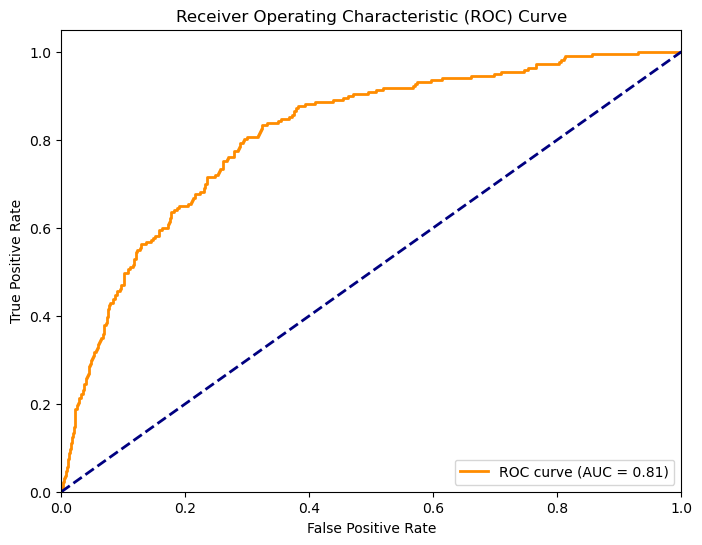

In [107]:
from sklearn.metrics import roc_curve, auc

import matplotlib.pyplot as plt

# Compute ROC curve and ROC area
fpr, tpr, thresholds = roc_curve(y_true, y_pred_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()